In [1]:
from pathlib import Path

ROOT = Path.cwd().parent
DATA = ROOT / "data"
RANDOM_STATE = 42
SUBMIT_TO_KAGGLE = False

In [2]:
import numpy as np
import pandas as pd
import timm
import torch
from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm

MODEL_NAME = "convnext_base.fb_in22k_ft_in1k_384"
BATCH_SIZE = 16
EMBEDDINGS_DIR = DATA / "embeddings"
DEVICE = torch.device("mps")

torch.manual_seed(RANDOM_STATE)

/Users/dmytro_lazarenko/PycharmProjects/deep-learning-assignment2/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# num_classes=0 removes the last layer, so the model returns the 1024 pooled features
model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=0).eval().to(DEVICE)
data_config = timm.data.resolve_data_config({}, model=model)
to_normalized_tensor = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=data_config["mean"], std=data_config["std"]),
])
data_config["mean"], data_config["std"]

((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))

In [4]:
def load_batch(image_dir: Path, image_ids: list[str]) -> torch.Tensor:
    """Load images as one normalized tensor. No resize, so all images must have the same size."""
    images = []
    for image_id in image_ids:
        with Image.open(image_dir / f"{image_id}.jpg") as image:
            images.append(to_normalized_tensor(image.convert("RGB")))
    return torch.stack(images)


@torch.inference_mode()
def embed_images(image_dir: Path, image_ids: list[str]) -> np.ndarray:
    """Return one embedding row per image id, in the same order."""
    batches = []
    for start in tqdm(range(0, len(image_ids), BATCH_SIZE)):
        batch = load_batch(image_dir, image_ids[start:start + BATCH_SIZE])
        batches.append(model(batch.to(DEVICE)).cpu().numpy())
    return np.concatenate(batches)


def save_split_embeddings(split: str) -> None:
    """Embed every image of the split and save the array to EMBEDDINGS_DIR/{split}.npy."""
    image_ids = pd.read_csv(DATA / f"{split}.csv")["image_id"].tolist()
    EMBEDDINGS_DIR.mkdir(exist_ok=True)
    np.save(EMBEDDINGS_DIR / f"{split}.npy", embed_images(DATA / split, image_ids))

In [5]:
# Smoke test on a few images; nothing is saved
sample_ids = pd.read_csv(DATA / "train.csv")["image_id"].tolist()[:5]
sample_embeddings = embed_images(DATA / "train", sample_ids)
print(sample_embeddings.shape, sample_embeddings.dtype, np.isfinite(sample_embeddings).all())
sample_embeddings[:, :5]

100%|██████████| 1/1 [00:00<00:00,  1.83it/s]

(5, 1024) float32 True


array([[-0.53038484,  0.83303064,  0.55366755,  0.7811622 , -0.25470862],
       [ 0.437998  ,  0.6642992 ,  0.59374106,  0.86405915, -0.465116  ],
       [-0.8291849 ,  1.7303973 ,  2.2988493 , -0.23909542,  0.56684035],
       [-0.93538   ,  0.8820587 , -0.09786308,  0.9376785 , -0.33089024],
       [ 0.07030281,  0.31795335, -1.2461593 , -0.32264596,  0.48937058]],
      dtype=float32)

In [6]:
for split in ("train", "test"):
    save_split_embeddings(split)

100%|██████████| 1168/1168 [11:18<00:00,  1.72it/s]


In [7]:
def describe_saved_embeddings(splits: tuple[str, ...]) -> pd.DataFrame:
    """Return one row per split with the shape of its saved array."""
    shapes = {split: np.load(EMBEDDINGS_DIR / f"{split}.npy").shape for split in splits}
    return pd.DataFrame(
        [(split, rows, columns) for split, (rows, columns) in shapes.items()],
        columns=["split", "rows", "columns"],
    )


describe_saved_embeddings(("train", "test"))

,split,rows,columns
0,train,12260,1024
1,test,18673,1024


In [8]:
def name_label_combination(label_columns: list[str], labels: tuple) -> str:
    """Join the names of the active labels, e.g. "Cat + Moris"."""
    return " + ".join(c for c, value in zip(label_columns, labels) if value == 1) or "No labels"


train = pd.read_csv(DATA / "train.csv")
label_columns = [column for column in train.columns if column != "image_id"]
combination_names = pd.Series(
    [name_label_combination(label_columns, labels) for labels in train[label_columns].itertuples(index=False)],
    name="combination",
)
train_embeddings = np.load(EMBEDDINGS_DIR / "train.npy")

In [9]:
def find_nearest_neighbor_indices(embeddings: np.ndarray) -> np.ndarray:
    """Return, for each row, the index of the most cosine-similar other row."""
    unit_embeddings = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)
    similarities = unit_embeddings @ unit_embeddings.T
    np.fill_diagonal(similarities, -np.inf)
    return similarities.argmax(axis=1)


def summarize_neighbor_agreement(combination_names: pd.Series, neighbor_indices: np.ndarray) -> pd.DataFrame:
    """Return one row per combination: photo count and % whose nearest photo has the same combination."""
    has_same_combination = combination_names.to_numpy() == combination_names.to_numpy()[neighbor_indices]
    return (
        pd.DataFrame({"combination": combination_names, "same": has_same_combination})
        .groupby("combination")["same"]
        .agg(photos="size", same_combination_pct=lambda same: round(100 * same.mean(), 1))
        .sort_values("photos", ascending=False)
        .reset_index()
    )

In [10]:
neighbor_indices = find_nearest_neighbor_indices(train_embeddings)
summarize_neighbor_agreement(combination_names, neighbor_indices)

,combination,photos,same_combination_pct
0,Cat,4989,99.5
1,Dog,4984,99.6
2,No labels,2162,99.8
3,Cat + Moris,42,78.6
4,Dog + Biatrix,37,100.0
5,Cat + Motya,32,81.2
6,Cat + Moris + Motya,10,30.0
7,Cat + Dog + Moris + Biatrix,4,75.0


In [11]:
EXIF_IFD_POINTER = 0x8769
DATE_TIME_ORIGINAL = 36867


def read_exif_flags(image_path: Path) -> tuple[bool, bool]:
    """Return (has_exif_block, has_capture_time) for one image."""
    with Image.open(image_path) as image:
        exif = image.getexif()
        # The capture time lives in the Exif sub-block, not in the main one
        has_capture_time = DATE_TIME_ORIGINAL in exif.get_ifd(EXIF_IFD_POINTER)
        return bool(exif), has_capture_time


def summarize_exif(split: str) -> dict[str, int | str]:
    """Return photo count, count with an EXIF block and count with a capture time for one split."""
    image_ids = pd.read_csv(DATA / f"{split}.csv")["image_id"]
    flags = [read_exif_flags(DATA / split / f"{image_id}.jpg") for image_id in image_ids]
    return {
        "split": split,
        "photos": len(flags),
        "with_exif": sum(has_exif for has_exif, _ in flags),
        "with_time": sum(has_time for _, has_time in flags),
    }

In [12]:
pd.DataFrame([summarize_exif(split) for split in ("train", "test")])

,split,photos,with_exif,with_time
0,train,12260,0,0
1,test,18673,0,0


In [13]:
import matplotlib.pyplot as plt

THRESHOLD_CANDIDATES = [0.98, 0.95, 0.9, 0.85, 0.8, 0.75, 0.7]
PAIRS_PER_CANDIDATE = 2


def build_nearest_pairs_table(embeddings: np.ndarray, neighbor_indices: np.ndarray) -> pd.DataFrame:
    """Return one row per unique (photo, nearest photo) pair with its cosine similarity."""
    unit_embeddings = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)
    photo_indices = np.arange(len(embeddings))
    pairs = pd.DataFrame({
        "first": np.minimum(photo_indices, neighbor_indices),
        "second": np.maximum(photo_indices, neighbor_indices),
        "cosine": (unit_embeddings * unit_embeddings[neighbor_indices]).sum(axis=1),
    })
    # Two photos that are each other's nearest give the same pair twice
    return pairs.drop_duplicates(["first", "second"])


def plot_pairs_closest_to_candidates(pairs: pd.DataFrame, image_ids: pd.Series, combination_names: pd.Series) -> None:
    """Draw one row per candidate threshold, with the pairs whose cosine is closest to it."""
    pair_width_ratios = [1, 1, 0.15] * PAIRS_PER_CANDIDATE
    fig, axes = plt.subplots(
        len(THRESHOLD_CANDIDATES), len(pair_width_ratios), figsize=(3 * PAIRS_PER_CANDIDATE * 2, 2.8 * len(THRESHOLD_CANDIDATES)),
        gridspec_kw={"width_ratios": pair_width_ratios},
    )
    for ax in axes.flat:
        ax.axis("off")

    for row, candidate in enumerate(THRESHOLD_CANDIDATES):
        closest = pairs.loc[(pairs["cosine"] - candidate).abs().nsmallest(PAIRS_PER_CANDIDATE).index]
        axes[row, 0].text(-0.05, 0.5, f"cosine ≈ {candidate}", transform=axes[row, 0].transAxes, ha="right", va="center", fontsize=12, fontweight="bold")
        for pair_number, pair in enumerate(closest.itertuples()):
            for side, photo_index in enumerate((pair.first, pair.second)):
                ax = axes[row, 3 * pair_number + side]
                ax.imshow(plt.imread(DATA / "train" / f"{image_ids[photo_index]}.jpg"))
                ax.set_title(f"{combination_names[photo_index]}\ncos {pair.cosine:.3f}", fontsize=9)

    fig.subplots_adjust(left=0.12, hspace=0.45)
    plt.show()

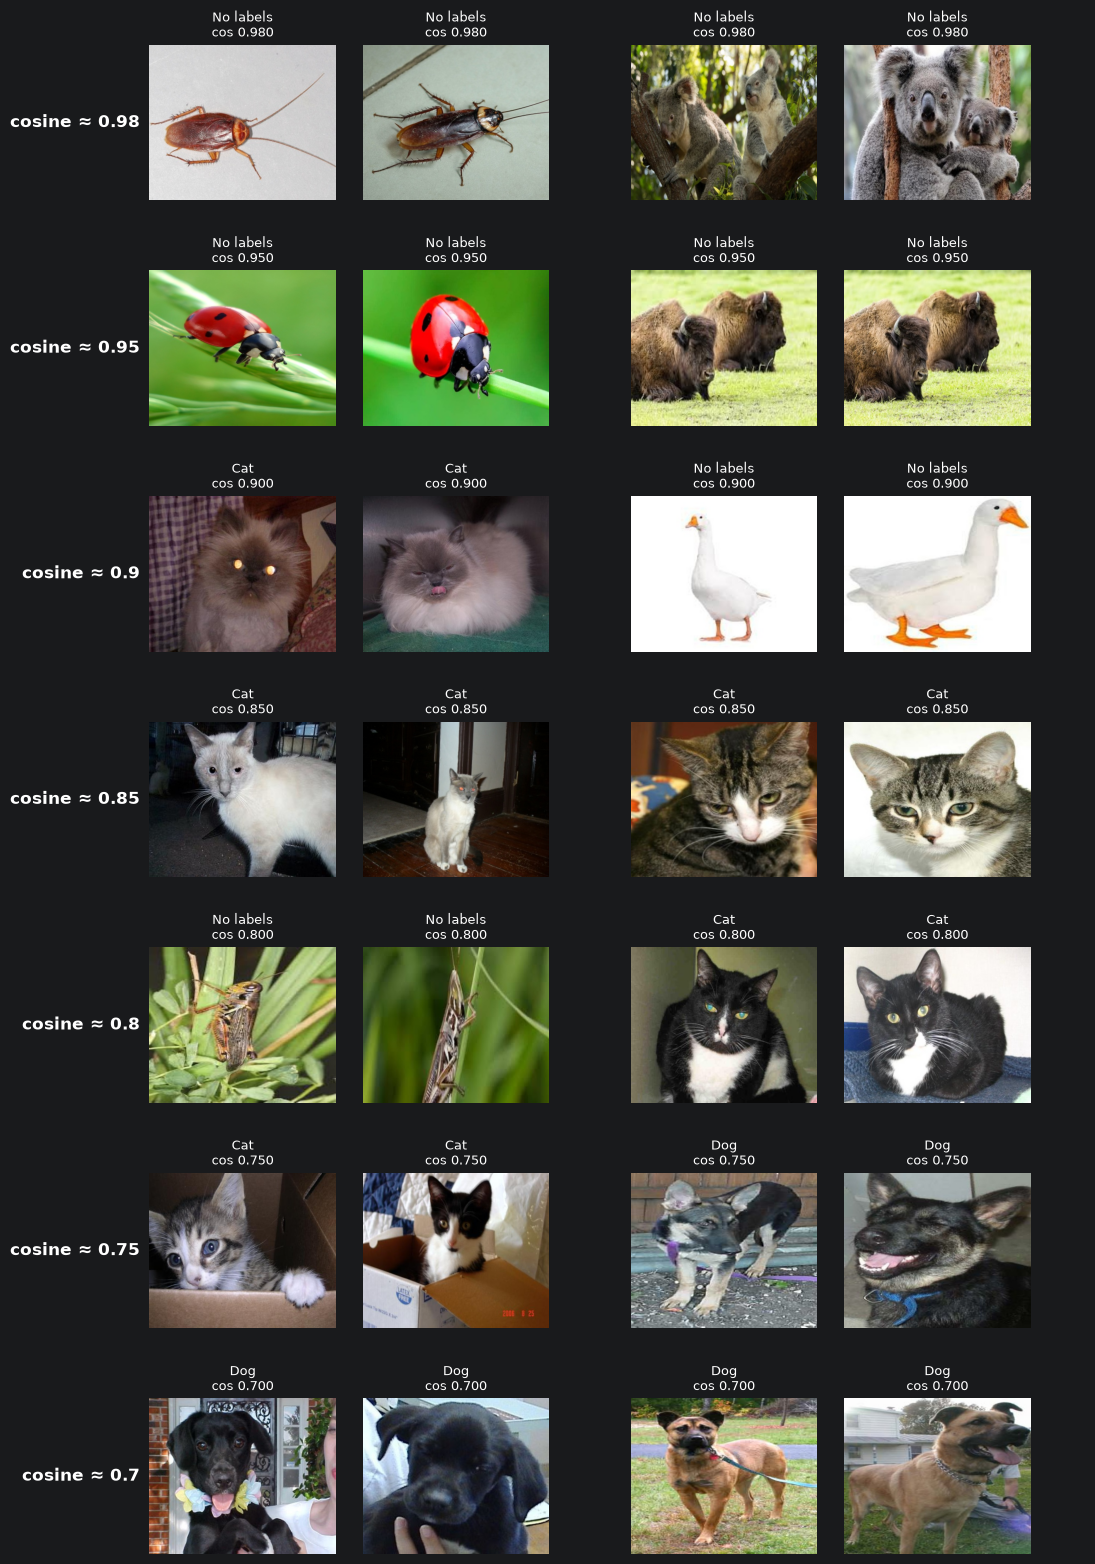

In [14]:
nearest_pairs = build_nearest_pairs_table(train_embeddings, neighbor_indices)
plot_pairs_closest_to_candidates(nearest_pairs, train["image_id"], combination_names)

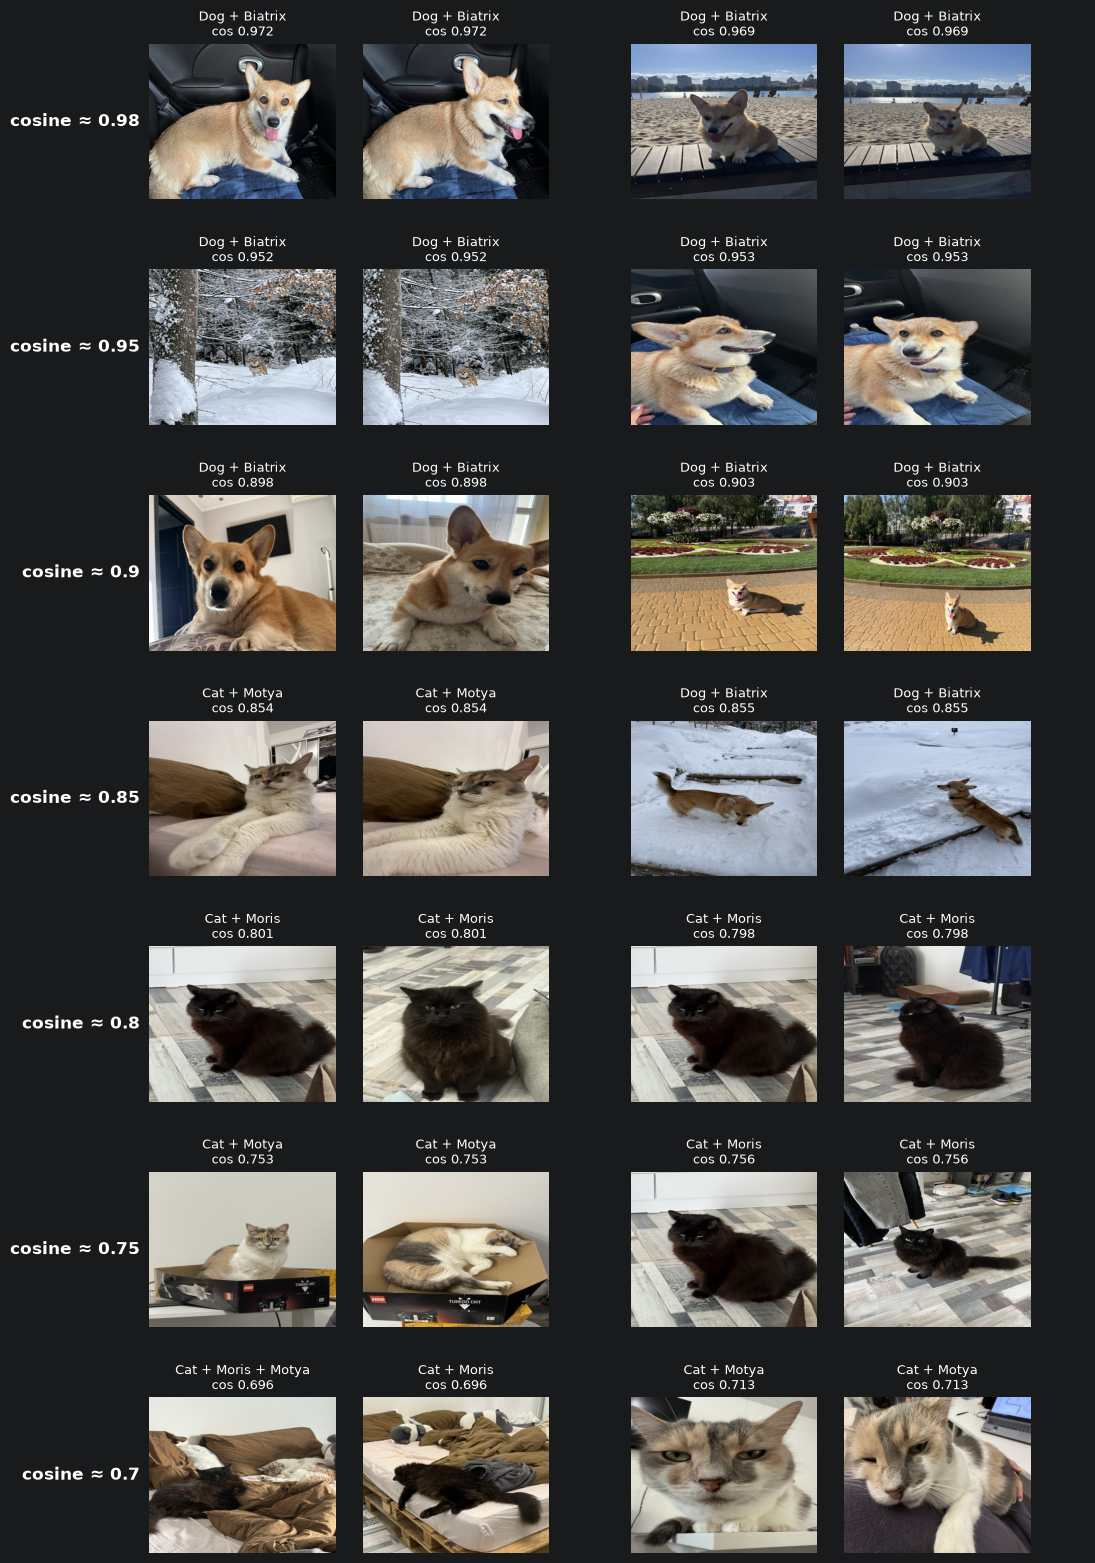

In [15]:
NAMED_PET_COLUMNS = ["Moris", "Motya", "Biatrix"]

has_named_pet = (train[NAMED_PET_COLUMNS] == 1).any(axis=1).to_numpy()
pet_embeddings = train_embeddings[has_named_pet]
pet_image_ids = train.loc[has_named_pet, "image_id"].reset_index(drop=True)
pet_combination_names = combination_names[has_named_pet].reset_index(drop=True)

pet_pairs = build_nearest_pairs_table(pet_embeddings, find_nearest_neighbor_indices(pet_embeddings))
plot_pairs_closest_to_candidates(pet_pairs, pet_image_ids, pet_combination_names)

In [16]:
NEAR_COPY_THRESHOLD = 0.95


def find_nearest_other_photos(embeddings: np.ndarray, query_indices: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """For each query row, return the index and the cosine of the most similar other row."""
    unit_embeddings = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)
    similarities = unit_embeddings[query_indices] @ unit_embeddings.T
    query_positions = np.arange(len(query_indices))
    similarities[query_positions, query_indices] = -np.inf
    nearest_indices = similarities.argmax(axis=1)
    return nearest_indices, similarities[query_positions, nearest_indices]


def summarize_near_copy_location(nearest_indices: np.ndarray, nearest_cosines: np.ndarray, train_size: int) -> pd.DataFrame:
    """Return photo counts by where the near copy is, with the share among near copies only."""
    has_near_copy = nearest_cosines >= NEAR_COPY_THRESHOLD
    is_in_train = nearest_indices < train_size
    counts = pd.Series({
        "near copy in train": (has_near_copy & is_in_train).sum(),
        "near copy in test": (has_near_copy & ~is_in_train).sum(),
        "no near copy": (~has_near_copy).sum(),
    })
    counts["total"] = counts.sum()
    near_copy_rows = ["near copy in train", "near copy in test"]
    near_copy_pct = (100 * counts[near_copy_rows] / counts[near_copy_rows].sum()).round(1)
    return pd.DataFrame({"photos": counts, "pct_of_near_copies": near_copy_pct.reindex(counts.index)})

In [17]:
test_embeddings = np.load(EMBEDDINGS_DIR / "test.npy")
all_embeddings = np.concatenate([train_embeddings, test_embeddings])
nearest_indices, nearest_cosines = find_nearest_other_photos(all_embeddings, np.flatnonzero(has_named_pet))
summarize_near_copy_location(nearest_indices, nearest_cosines, len(train_embeddings))

,photos,pct_of_near_copies
near copy in train,7,31.8
near copy in test,15,68.2
no near copy,103,NaN
total,125,NaN


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

N_SPLITS = 5


def cross_validate_train_vs_test(embeddings: np.ndarray, is_test: np.ndarray) -> pd.Series:
    """Return the ROC AUC of each validation fold for a model that predicts test (1) vs train (0)."""
    folds = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    scores = []
    for train_indices, valid_indices in folds.split(embeddings, is_test):
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
        model.fit(embeddings[train_indices], is_test[train_indices])
        scores.append(roc_auc_score(is_test[valid_indices], model.predict_proba(embeddings[valid_indices])[:, 1]))
    return pd.Series(scores, index=[f"fold_{number}" for number in range(N_SPLITS)])

In [19]:
is_test = np.r_[np.zeros(len(train_embeddings)), np.ones(len(test_embeddings))].astype(int)
fold_scores = cross_validate_train_vs_test(all_embeddings, is_test)
fold_scores["mean"] = fold_scores.mean()
fold_scores

fold_0    0.497352
fold_1    0.502056
fold_2    0.494076
fold_3    0.509064
fold_4    0.502158
mean      0.500941
dtype: float64

In [20]:
FOLDS_PATH = ROOT / "folds.csv"


def assign_folds(image_ids: pd.Series, combination_names: pd.Series) -> pd.DataFrame:
    """Return image_id and fold (0-4), with each label combination spread evenly over the folds."""
    folds = pd.Series(-1, index=image_ids.index, name="fold")
    splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    for fold, (_, valid_indices) in enumerate(splitter.split(image_ids, combination_names)):
        folds.iloc[valid_indices] = fold
    return pd.concat([image_ids, folds], axis=1)

In [21]:
train_folds = assign_folds(train["image_id"], combination_names)
train_folds.to_csv(FOLDS_PATH, index=False)
pd.crosstab(combination_names, train_folds["fold"])

/Users/dmytro_lazarenko/PycharmProjects/deep-learning-assignment2/.venv/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


fold,0,1,2,3,4
combination,,,,,
Cat,998,997,998,998,998
Cat + Dog + Moris + Biatrix,0,1,1,1,1
Cat + Moris,8,8,9,9,8
Cat + Moris + Motya,2,2,2,2,2
Cat + Motya,7,6,6,6,7
Dog,996,997,997,997,997
Dog + Biatrix,8,8,7,7,7
No labels,433,433,432,432,432


In [22]:
FINAL_THRESHOLD = 0.25


def predict_test_probabilities(train_embeddings: np.ndarray, y_true: pd.DataFrame, test_embeddings: np.ndarray) -> pd.DataFrame:
    """Return P(label=1) for each test photo, from one model per label trained on all train photos."""
    probabilities = {}
    for column in y_true.columns:
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
        model.fit(train_embeddings, y_true[column])
        probabilities[column] = model.predict_proba(test_embeddings)[:, 1]
    return pd.DataFrame(probabilities)


def compare_expected_and_predicted_counts(y_true: pd.DataFrame, test_probabilities: pd.DataFrame, threshold: float) -> pd.DataFrame:
    """Return per label: the test count expected from the train share, and the test photos above the threshold."""
    return pd.DataFrame({
        "expected_count": y_true.mean() * len(test_probabilities),
        f"predicted_above_{threshold}": (test_probabilities > threshold).sum(),
    })

In [23]:
test_probabilities = predict_test_probabilities(train_embeddings, train[label_columns], test_embeddings)
compare_expected_and_predicted_counts(train[label_columns], test_probabilities, FINAL_THRESHOLD)

,expected_count,predicted_above_0.25
Cat,7732.693393,7771
Dog,7653.493067,7681
Moris,85.292659,169
Motya,63.969494,115
Biatrix,62.446411,184


In [24]:
SUBMISSIONS_DIR = ROOT / "submissions"


def build_submission(image_ids: pd.Series, test_probabilities: pd.DataFrame, threshold: float) -> pd.DataFrame:
    """Return image_id and the 0/1 prediction of each label, in the sample_submission format."""
    return pd.concat([image_ids, (test_probabilities > threshold).astype(int)], axis=1)

In [25]:
test = pd.read_csv(DATA / "test.csv")
submission = build_submission(test["image_id"], test_probabilities, FINAL_THRESHOLD)
SUBMISSIONS_DIR.mkdir(exist_ok=True)
submission.to_csv(SUBMISSIONS_DIR / "logreg_025.csv", index=False)
submission.head()

,image_id,Cat,Dog,Moris,Motya,Biatrix
0,12c79b0a4bd444ca7e5f730b86824b9279d3cd24,0,0,0,0,0
1,dd9440332972c9c5cecb5bf3cfb3329d6b2e422c,0,1,0,0,0
2,ac89f642faef21c92d622d882943e9065600354a,0,0,0,0,0
3,7245e7046ae54da95dbddc24ae814b3c61cc6237,1,0,0,0,0
4,d2b76179615de57b54cb00d094fba50810d96127,1,0,0,0,0


In [ ]:
if SUBMIT_TO_KAGGLE:
    !kaggle competitions submit -c cats-and-dogs -f ../submissions/logreg_025.csv -m "logreg per label on convnext_base embeddings, threshold 0.25"
else:
    print("Kaggle submission skipped. Set SUBMIT_TO_KAGGLE = True to submit.")

In [29]:
FIXED_THRESHOLD = 0.5

submission_05 = build_submission(test["image_id"], test_probabilities, FIXED_THRESHOLD)
submission_05.to_csv(SUBMISSIONS_DIR / "logreg_05.csv", index=False)
submission_05.iloc[:, 1:].sum()

Cat        7754
Dog        7666
Moris       131
Motya       100
Biatrix     177
dtype: int64

In [ ]:
if SUBMIT_TO_KAGGLE:
    !kaggle competitions submit -c cats-and-dogs -f ../submissions/logreg_05.csv -m "logreg per label on convnext_base embeddings, threshold 0.5"
else:
    print("Kaggle submission skipped. Set SUBMIT_TO_KAGGLE = True to submit.")

## Conclusions

**Model choice**
- ConvNeXt is a strong CNN of recent years. It is pretrained on ImageNet, so the assignment allows it.
- ConvNeXt has several sizes. I chose `convnext_base` as a balance between top-1 accuracy and the number of parameters.
- This version was trained on 384x384 images, which is close to our 450x375 images. We use the images without resize or crop, so we lose very little information.

**Embeddings**
- We made the embeddings (1024 numbers per image) only to run the similarity check: the nearest train photo by cosine similarity, skipping the photo itself.
- The embeddings look healthy. The 3 majority classes (Cat, Dog, No labels) have 99+% of nearest photos with the same combination.

**Majority classes**
- No labels is the highest (99.8%). Its photos are far from cats and dogs, so even if a lobster is matched with a horse, the combination is still correct.

**Named pets**
- Moris and Motya give a not bad result (79% and 81%). Probably the embeddings catch the home or the environment of the photos. This cause is not confirmed.
- Biatrix is very high: all 37 photos (100%) have the same combination as the nearest photo. The reason is not clear. Maybe the photos are very similar to each other, or maybe the dog looks unique, so photos with a similar background are not close to it.
- Cat + Moris + Motya (30%, 10 photos) is the weakest. Probably the nearest photo is often one of the two cats alone, which counts as a wrong combination. With 10 photos, one photo changes the result by 10 points.

**EXIF data**
- No photo in train (12260) or test (18673) has an EXIF block. The capture time is not available.
- We cannot find photo series by time. We can search for them only by cosine similarity of the embeddings.

**Near-copy threshold**
- We compared the nearest-photo pairs by eye, for all train photos and for the named pets only.
- For the named pets, the two photos of a pair show the same scene at a cosine of 0.95 and higher.
- This does not hold for all train photos. We use the threshold only for the named pets.
- Below 0.95, several named-pet pairs still show similar scenes. A threshold of 0.95 would miss them.
- The final threshold is not chosen yet.

**Near copies between train and test**
- For the named-pet train photos, we looked for the most similar other photo in train and test together. The threshold is 0.95.
- 22 of 125 photos have a near copy. 15 of them (68%) have it in test, and 7 (32%) have it in train.
- Test holds 60% of all photos (18673 of 30933). The 68% is not far from this share.
- So near copies of the named pets are spread over train and test about as much as plain chance gives.
- The test set also has near copies of the train photos. A validation fold that has near copies in train then looks like the test set.
- Probably we do not need to keep near copies in the same fold. A plain stratified split is enough. This is not confirmed.
- Only 22 photos have a near copy, so one photo changes the percent by about 5 points.

**Adversarial validation**
- We trained a logistic regression to tell train photos (0) from test photos (1). We used the embeddings and 5 stratified shuffled folds.
- The ROC AUC is 0.501 on average, and each fold is between 0.494 and 0.509. This is near 0.5.
- So the model cannot tell train photos from test photos.
- We keep the same strategy: a stratified 5-fold split. We need no additional action.

**Test predictions: logistic regression**
- We trained one logistic regression for each label on all train photos. Then we predicted the test photos with the threshold 0.25.
- We compared the predicted counts with the counts expected from the train share (train share times 18673 test photos).
- Cat and Dog match almost exactly. Cat: 7771 predicted, 7733 expected. Dog: 7681 predicted, 7653 expected.
- The named pets get 2 to 3 times more photos than expected. Moris: 169 against 85. Motya: 115 against 64. Biatrix: 184 against 62.
- We repeated this with the threshold 0.5. The result is the same, but the counts are lower. Moris: 131. Motya: 100. Biatrix: 177.

**CV against leaderboard**
- The Kaggle score at 0.25 is 0.92922. At 0.5 it is 0.92186.
- The CV score is higher in both cases: 0.957 (fair check) at 0.25 and 0.943 at 0.5. The gap is about 0.03 and 0.02.
- The threshold 0.25 is better on both CV and the leaderboard. The choice holds on data that the model did not see.

**Reason for the gap**
- Our assumption: the test set has more photos of the named pets than the train set.
- The model learned from train that the named pets are very rare. On test it can give them too low probabilities and miss some photos.
- This is not confirmed. The named-pet photos in test can come from other scenes. I think this is not the case.
- If the extra named-pet predictions were false alarms, the leaderboard score would fall and the gap would be bigger. The score is about 0.92, so most of these photos are probably real pets.

**Decision**
- We compare models by CV macro F1. We call two results similar if they differ by less than 0.005.
- We expect the leaderboard score to be 0.02 to 0.03 lower than CV.
- We keep the threshold 0.25.
